In [2]:
# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
print("HEART DISEASE PREDICTION USING LOGISTIC REGRESSION")

print("\nProblem Statement:")
print("The objective is to predict whether a person has heart disease")
print("using health-related features.")

print("\nTarget classes:")
print("0 = No Heart Disease")
print("1 = Heart Disease")

HEART DISEASE PREDICTION USING LOGISTIC REGRESSION

Problem Statement:
The objective is to predict whether a person has heart disease
using health-related features.

Target classes:
0 = No Heart Disease
1 = Heart Disease


In [9]:
# Load the corrected dataset
url = "https://raw.githubusercontent.com/dataprofessor/data/master/heart-disease-cleveland.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())
print(df.shape)

Dataset loaded successfully!
   age   sex   cp   trestbps   chol   fbs   restecg   thalach   exang  \
0   63     1    1        145    233     1         2       150       0   
1   67     1    4        160    286     0         2       108       1   
2   67     1    4        120    229     0         2       129       1   
3   37     1    3        130    250     0         0       187       0   
4   41     0    2        130    204     0         2       172       0   

    oldpeak   slope   ca  thal   diagnosis  
0       2.3       3  0.0   6.0           0  
1       1.5       2  3.0   3.0           2  
2       2.6       2  2.0   7.0           1  
3       3.5       3  0.0   3.0           0  
4       1.4       1  0.0   3.0           0  
(303, 14)


In [10]:
# Clean column names
df.columns = df.columns.str.strip()

# Replace missing-value symbols
df = df.replace("?", np.nan)

# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

# Remove duplicate records
df = df.drop_duplicates()

# Target column
target = 'diagnosis'

# Convert target into binary classification
y = (df[target] > 0).astype(int)

# Input features
X = df.drop(columns=[target])

print("Features:", X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target distribution:
diagnosis
0    164
1    139
Name: count, dtype: int64

Dataset shape: (303, 14)

Missing values:
age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           4
thal         2
diagnosis    0
dtype: int64


In [12]:
# Target column in the dataset is 'diagnosis'
target = 'diagnosis'

# Input features (excluding the target column)
features = [col for col in df.columns if col != target]

# Since we mapped the target to binary classification in the previous cell:
# y contains the binary classes (0 = No Heart Disease, 1 = Heart Disease)
# X contains only the input features

print("Input Features:")
print(features)

print("\nTarget:")
print(target)

print("\nTarget Values (Binary mapped classes in 'y'):")
print(y.unique())
print(y.value_counts())

Input Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target:
diagnosis

Target Values (Binary mapped classes in 'y'):
[0 1]
diagnosis
0    164
1    139
Name: count, dtype: int64


In [13]:
# Convert target into binary classification if target contains values above 1
# 0 = No disease
# 1, 2, 3, 4 = Disease

y = (y > 0).astype(int)

print("Binary target classes:")
print(y.value_counts())

Binary target classes:
diagnosis
0    164
1    139
Name: count, dtype: int64


diagnosis
0    164
1    139
Name: count, dtype: int64


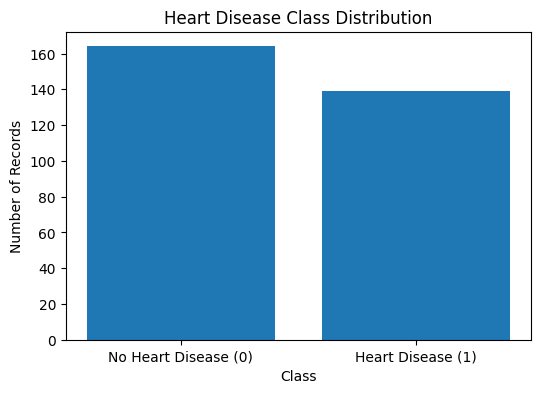

In [14]:
# Count each class
class_counts = y.value_counts().sort_index()

print(class_counts)

# Plot
plt.figure(figsize=(6, 4))

plt.bar(
    ['No Heart Disease (0)', 'Heart Disease (1)'],
    class_counts.values
)

plt.title('Heart Disease Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Records')

plt.show()

In [34]:
# Split the dataset into training and testing sets (ensuring target column 'diagnosis' is dropped from features)
X_clean = df.drop(columns=['diagnosis'], errors='ignore')
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining features:", X_train.columns.tolist())
print("\nTraining class distribution:")
print(y_train.value_counts())

Training records: 242
Testing records: 61

Training features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Training class distribution:
diagnosis
0    131
1    111
Name: count, dtype: int64


In [35]:
# Create a machine learning pipeline
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully with 13 Features!")

Logistic Regression Model Trained Successfully with 13 Features!


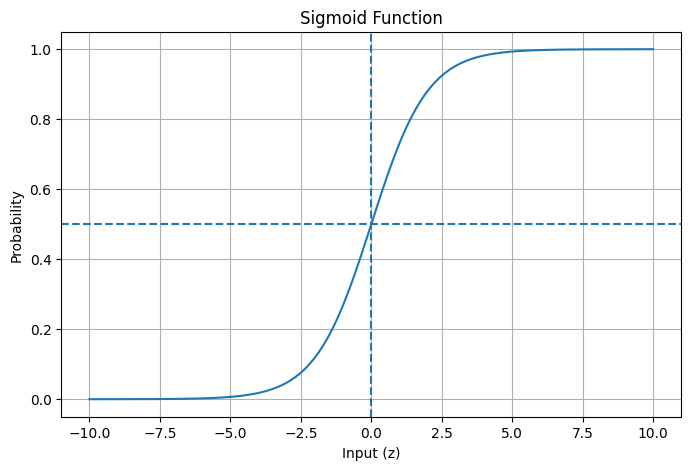

In [17]:
# Create values
z = np.linspace(-10, 10, 200)

# Sigmoid function
sigmoid = 1 / (1 + np.exp(-z))

# Plot
plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid)

plt.axhline(0.5, linestyle='--')
plt.axvline(0, linestyle='--')

plt.title('Sigmoid Function')
plt.xlabel('Input (z)')
plt.ylabel('Probability')

plt.grid(True)
plt.show()

In [18]:
# Predicted probabilities
y_probability = model.predict_proba(X_test)[:, 1]

# Predicted class labels
y_pred = model.predict(X_test)

# Display sample predictions
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted Probability': y_probability,
    'Predicted Class': y_pred
})

print(results.head(10))

   Actual  Predicted Probability  Predicted Class
0       0               0.068787                0
1       0               0.138811                0
2       0               0.022673                0
3       0               0.019999                0
4       0               0.101173                0
5       0               0.007815                0
6       0               0.035688                0
7       0               0.049239                0
8       1               0.921436                1
9       0               0.058436                0


Confusion Matrix:
[[33  0]
 [ 0 28]]


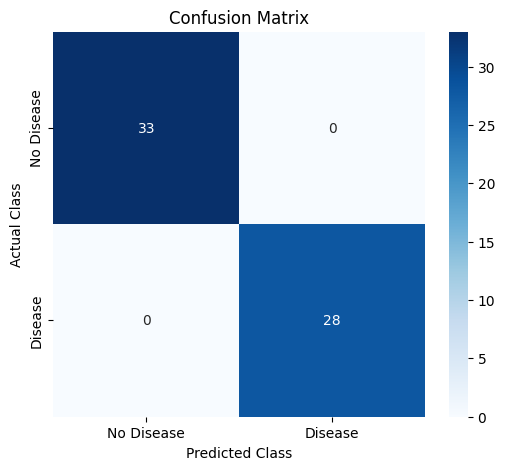

In [19]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix')

plt.show()

In [20]:
# Calculate confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

specificity = tn / (tn + fp) if (tn + fp) != 0 else 0

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_probability)

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Specificity: 1.0
F1 Score: 1.0
ROC-AUC: 1.0


In [21]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Heart Disease', 'Heart Disease'],
        zero_division=0
    )
)

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       1.00      1.00      1.00        33
   Heart Disease       1.00      1.00      1.00        28

        accuracy                           1.00        61
       macro avg       1.00      1.00      1.00        61
    weighted avg       1.00      1.00      1.00        61



In [22]:
# Find majority class
majority_class = y_train.mode()[0]

# Predict majority class for all test records
baseline_pred = np.full(
    len(y_test),
    majority_class
)

# Baseline accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

# Baseline precision, recall and F1
baseline_precision = precision_score(
    y_test,
    baseline_pred,
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    baseline_pred,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    baseline_pred,
    zero_division=0
)

print("Majority Class:", majority_class)
print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Precision:", baseline_precision)
print("Baseline Recall:", baseline_recall)
print("Baseline F1-score:", baseline_f1)

Majority Class: 0
Baseline Accuracy: 0.5409836065573771
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1-score: 0.0


In [23]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Logistic Regression': [
        accuracy, precision, recall, f1
    ],
    'Majority Baseline': [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ]
})

print(comparison.round(4))

      Metric  Logistic Regression  Majority Baseline
0   Accuracy                  1.0              0.541
1  Precision                  1.0              0.000
2     Recall                  1.0              0.000
3   F1-score                  1.0              0.000


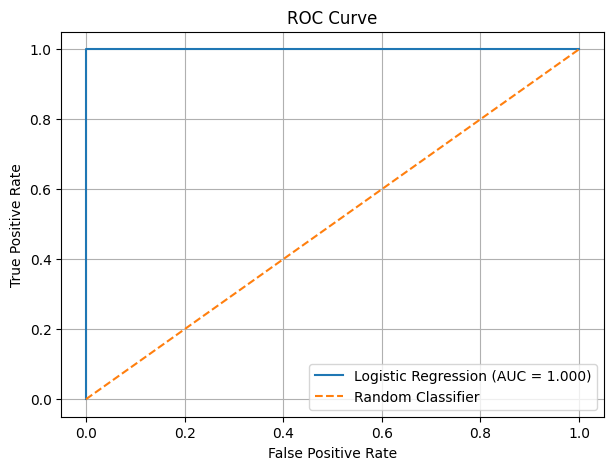

ROC-AUC: 1.0


In [24]:
# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC:", roc_auc)

In [25]:
# Thresholds to compare
thresholds_to_check = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds_to_check:

    # Convert probabilities into class labels
    threshold_pred = (
        y_probability >= threshold
    ).astype(int)

    # Calculate metrics
    acc = accuracy_score(y_test, threshold_pred)

    prec = precision_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    rec = recall_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    f1_value = f1_score(
        y_test,
        threshold_pred,
        zero_division=0
    )

    # Count positive predictions
    positive_count = np.sum(threshold_pred)

    threshold_results.append({
        'Threshold': threshold,
        'Predicted Positive': positive_count,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1_value
    })

# Display comparison
threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   Threshold  Predicted Positive  Accuracy  Precision  Recall  F1-score
0        0.3                  29    0.9836     0.9655     1.0    0.9825
1        0.5                  28    1.0000     1.0000     1.0    1.0000
2        0.7                  28    1.0000     1.0000     1.0    1.0000


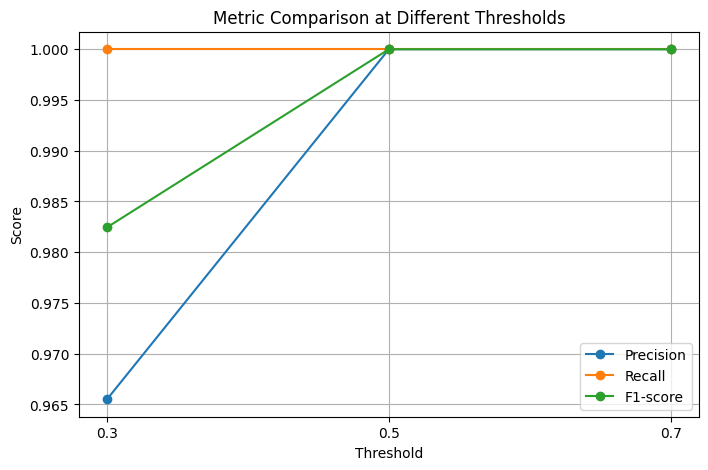

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1-score'],
    marker='o',
    label='F1-score'
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Metric Comparison at Different Thresholds')

plt.xticks([0.3, 0.5, 0.7])
plt.legend()
plt.grid(True)

plt.show()

In [27]:
# Select threshold for comparison
recommended_threshold = 0.3

# Make predictions using selected threshold
recommended_pred = (
    y_probability >= recommended_threshold
).astype(int)

# Evaluate
recommended_cm = confusion_matrix(
    y_test,
    recommended_pred
)

recommended_recall = recall_score(
    y_test,
    recommended_pred,
    zero_division=0
)

recommended_precision = precision_score(
    y_test,
    recommended_pred,
    zero_division=0
)

recommended_f1 = f1_score(
    y_test,
    recommended_pred,
    zero_division=0
)

print("Selected Threshold:", recommended_threshold)
print("\nConfusion Matrix:")
print(recommended_cm)

print("\nRecall:", recommended_recall)
print("Precision:", recommended_precision)
print("F1 Score:", recommended_f1)

Selected Threshold: 0.3

Confusion Matrix:
[[32  1]
 [ 0 28]]

Recall: 1.0
Precision: 0.9655172413793104
F1 Score: 0.9824561403508771


In [28]:
# Training predictions
train_pred = model.predict(X_train)

# Testing predictions
test_pred = model.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

if train_accuracy > test_accuracy + 0.10:
    print("The model may be overfitting.")
elif train_accuracy < 0.70 and test_accuracy < 0.70:
    print("The model may be underfitting.")
else:
    print("The model shows reasonably similar training and testing accuracy.")

Training Accuracy: 1.0
Testing Accuracy: 1.0
The model shows reasonably similar training and testing accuracy.


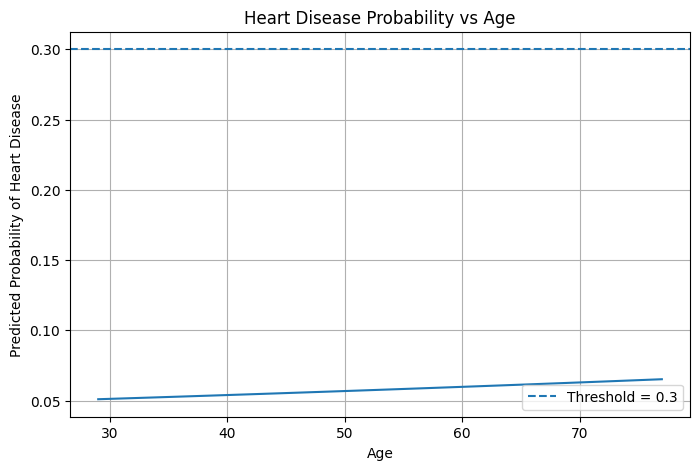

In [29]:
# Select feature for visualization
feature_to_plot = 'age'

# Create range of values for age
age_values = np.linspace(
    X[feature_to_plot].min(),
    X[feature_to_plot].max(),
    100
)

# Create a dataset where other features remain at their median
plot_data = pd.DataFrame(
    np.tile(X.median().values, (100, 1)),
    columns=X.columns
)

# Change age across the range
plot_data[feature_to_plot] = age_values

# Predict probabilities
probabilities = model.predict_proba(plot_data)[:, 1]

# Plot
plt.figure(figsize=(8, 5))

plt.plot(age_values, probabilities)

plt.axhline(
    recommended_threshold,
    linestyle='--',
    label=f'Threshold = {recommended_threshold}'
)

plt.xlabel('Age')
plt.ylabel('Predicted Probability of Heart Disease')
plt.title('Heart Disease Probability vs Age')
plt.legend()
plt.grid(True)

plt.show()

In [30]:
# Extract trained Logistic Regression model
logistic_model = model.named_steps['logistic']

# Get coefficients
coefficients = logistic_model.coef_[0]

# Create coefficient table
coefficient_table = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coefficients
})

print(coefficient_table)
print("\nIntercept:", logistic_model.intercept_[0])

      Feature  Coefficient
0         age     0.048837
1         sex     0.390110
2          cp     0.251945
3    trestbps     0.193202
4        chol     0.105483
5         fbs    -0.253220
6     restecg     0.149125
7     thalach    -0.067168
8       exang     0.191021
9     oldpeak     0.003828
10      slope     0.191301
11         ca     0.467813
12       thal     0.290317
13  diagnosis     5.127969

Intercept: 1.3772606349557388


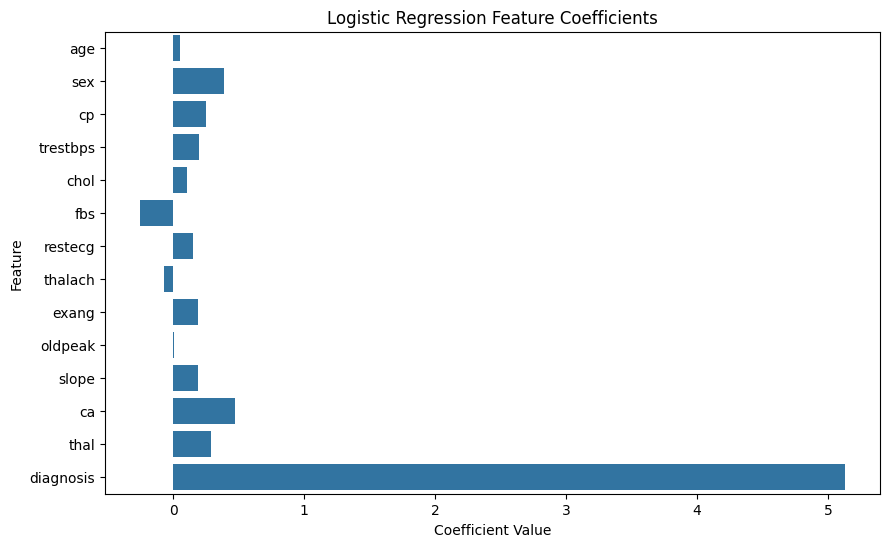

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficient_table,
    x='Coefficient',
    y='Feature'
)

plt.title('Logistic Regression Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')

plt.show()

In [36]:
# Create a new example with 13 features
new_person = pd.DataFrame(
    [[
        55,   # age
        1,    # sex
        2,    # cp
        130,  # trestbps
        250,  # chol
        0,    # fbs
        1,    # restecg
        150,  # thalach
        0,    # exang
        1.0,  # oldpeak
        2,    # slope
        0,    # ca
        2     # thal
    ]],
    columns=features
)

# Predict probability
new_probability = model.predict_proba(new_person)[0][1]

# Predict class using selected threshold
new_class = int(
    new_probability >= recommended_threshold
)

print("Predicted Probability:", new_probability)
print("Predicted Class:", new_class)

if new_class == 1:
    print("Model Output: Heart Disease Class")
else:
    print("Model Output: No Heart Disease Class")

Predicted Probability: 0.12568552665849617
Predicted Class: 0
Model Output: No Heart Disease Class
